# Votação por maioria — Random Forest, RNN e Modelo 8

Três modelos que respondem à mesma pergunta votam, linha a linha, se a porta terá uma corretiva emergencial **ZM01 nos próximos 7 dias**. Cada um vota `True` ou `False` com o limiar que escolheu na própria validação. A previsão final é a da maioria: **2 votos de 3** viram alerta.

Os votantes precisam prever as mesmas linhas. Por isso entram só modelos do painel porta-dia do Modelo 5 (`models/modelo-5/painel.parquet`), com o mesmo teste (a partir de 01/05/2025, 71.184 linhas). Os Modelos 6 e 7 ficam fora: o alvo deles é outro (sistema PSD inteiro, não a porta), então os números não se comparam nem se somam.

| Votante | Família | Origem do voto |
|---|---|---|
| Random Forest (Modelo 5) | árvores em bagging | bundle de produção `src/modelo/artifacts/modelo_5.joblib` |
| RNN otimizada + extras | GRU de 2 camadas sobre 30 dias + histórico SAP | `models/modelo-rnn-otimizado/` |
| Modelo 8 | Isolation Forest + cabeças supervisionadas | retreinado aqui, mesmo código de `models/modelo-8/modelo_8.ipynb` |

O Modelo 5.1 (Random Forest sem `num_porta`) tem F1 um pouco maior que o Modelo 8, mas é o mesmo Random Forest com uma feature a menos. Os dois votariam quase sempre juntos e o Random Forest decidiria sozinho. A votação só corrige erro quando os votantes erram em lugares diferentes, então a escolha priorizou três famílias distintas.

Nenhum limiar é reajustado no teste. As métricas são acurácia, precisão, recall e F1 da classe 1, por linha (porta-dia).

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import (
    ExtraTreesClassifier,
    HistGradientBoostingClassifier,
    IsolationForest,
    RandomForestClassifier,
)
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)
from sklearn.preprocessing import QuantileTransformer

raiz = Path.cwd()
if not (raiz / 'models' / 'modelo-5' / 'painel.parquet').exists():
    for pasta in Path.cwd().parents:
        if (pasta / 'models' / 'modelo-5' / 'painel.parquet').exists():
            raiz = pasta
            break

## 1. Votantes 1 e 2 — Random Forest e RNN

As previsões dos dois no teste já foram geradas por `models/modelo-rnn-otimizado/avaliar_ensemble.py`: o Random Forest é o bundle de produção, com o limiar salvo nele; a RNN é a configuração da Etapa 2, semente 42, limiar 0,6555 escolhido na validação. Reaproveitar o arquivo evita depender de PyTorch aqui e garante que o voto é o mesmo já documentado.

In [2]:
rf_rnn = pd.read_parquet(raiz / 'models' / 'modelo-rnn-otimizado' / 'ensemble_previsoes_teste.parquet')
rf_rnn = rf_rnn[['id_porta', 'Data', 'y', 'prob_rf', 'alerta_rf', 'prob_rnn', 'alerta_rnn']]
rf_rnn['Data'] = pd.to_datetime(rf_rnn['Data'])
print(f'{len(rf_rnn):,} linhas | {rf_rnn["Data"].min().date()} -> {rf_rnn["Data"].max().date()}')
print(f'alertas RF: {rf_rnn["alerta_rf"].sum():,} | alertas RNN: {rf_rnn["alerta_rnn"].sum():,}')

71,184 linhas | 2025-05-01 -> 2025-10-31
alertas RF: 24,019 | alertas RNN: 26,492


## 2. Votante 3 — Modelo 8

O Modelo 8 não tem artefato salvo, então é retreinado com o código do notebook original, célula por célula: features de ritmo e desvio, split temporal com folga de 7 dias, Isolation Forest só nos dias quietos e, por cima do score `iso`, Random Forest, Extra Trees, HistGradientBoosting e o blend. Vence quem tiver o melhor F1 na validação; o limiar dele é o voto.

In [3]:
painel = pd.read_parquet(raiz / 'models' / 'modelo-5' / 'painel.parquet')
painel['Data'] = pd.to_datetime(painel['Data'])
painel = painel.sort_values(['Data', 'id_porta']).reset_index(drop=True)
assert painel['Data'].is_monotonic_increasing

In [4]:
PROIBIDAS = {'n_falhas_7d_futuro'}
EPS = 1.0

for prefixo in ('n_total', 'n_LSD', 'n_tecnicos', 'n_long30', 'n_FO', 'n_FC', 'n_RCE'):
    painel[f'rampa_{prefixo}'] = painel[f'{prefixo}_7d'] - (painel[f'{prefixo}_14d'] - painel[f'{prefixo}_7d'])

painel['razao_7_30'] = painel['n_total_7d'] / (painel['n_total_30d'] / 4 + EPS)
painel['razao_lsd_7_30'] = painel['n_LSD_7d'] / (painel['n_LSD_30d'] / 4 + EPS)
painel['razao_tec_7_30'] = painel['n_tecnicos_7d'] / (painel['n_tecnicos_30d'] / 4 + EPS)
painel['frac_tec_7'] = painel['n_tecnicos_7d'] / (painel['n_total_7d'] + EPS)
painel['frac_lsd_7'] = painel['n_LSD_7d'] / (painel['n_tecnicos_7d'] + EPS)
painel['frac_long_7'] = painel['n_long30_7d'] / (painel['n_total_7d'] + EPS)
painel['frac_fo_7'] = painel['n_FO_7d'] / (painel['n_tecnicos_7d'] + EPS)
painel['intensidade_7'] = np.log1p(painel['dur_max_7d']) / (painel['n_total_7d'] + EPS)
painel['lsd_x_dur'] = painel['n_LSD_7d'] * np.log1p(painel['dur_max_7d'])
painel['tec_x_dur'] = painel['n_tecnicos_7d'] * np.log1p(painel['dur_max_7d'])
painel['frescor_total'] = painel['n_total_decaido_h3'] / (painel['n_total_decaido_h14'] + EPS)
painel['frescor_lsd'] = painel['n_LSD_decaido_h7'] / (painel['n_LSD_7d'] + EPS)

tipos_7d = ['n_CA_7d', 'n_CSD_7d', 'n_FC_7d', 'n_FO_7d', 'n_LSD_7d', 'n_OA_7d', 'n_OBS_7d', 'n_RCE_7d']
painel['n_tipos_7d'] = (painel[tipos_7d] > 0).sum(axis=1)

for origem, dest in (
    ('dias_desde_zm01', 'rec_zm01'),
    ('dias_desde_zm02', 'rec_zm02'),
    ('dias_desde_zm03', 'rec_zm03'),
):
    dias = painel[origem].replace(9999, np.nan).clip(upper=365).fillna(365)
    painel[dest] = np.exp(-dias / 30.0)

painel['rec_ultima_corretiva'] = np.maximum(painel['rec_zm01'], painel['rec_zm02'])
painel['zm01_concentracao'] = painel['zm01_30d'] / (painel['zm01_90d'] / 3 + EPS)
dias_z = painel['dias_desde_zm01'].replace(9999, 365).clip(0, 365)
painel['razao_atraso'] = dias_z / (90.0 / painel['zm01_90d'].clip(lower=0.5))

for col in ('n_tecnicos_7d', 'n_LSD_7d', 'dur_max_7d', 'n_long30_7d'):
    g = painel.groupby(['est', 'Data'])[col]
    med = g.transform('median')
    std = g.transform('std').replace(0, np.nan).fillna(1.0)
    painel[f'zest_{col}'] = ((painel[col] - med) / std).clip(-8, 8)

id_cols = {
    'id_porta', 'Data', 'est', 'via', 'id_plat', 'y', 'cobertura_30d',
    'mes', 'dia_semana', 'fim_de_semana', 'num_porta',
}
candidatas = [
    c for c in painel.columns
    if c not in PROIBIDAS and c not in id_cols
    and not c.startswith('dias_desde_')
    and not c.endswith(('_1d', '_3d'))
    and pd.api.types.is_numeric_dtype(painel[c])
]
print(len(candidatas), 'candidatas')

76 candidatas


In [5]:
FIM_FIT = pd.Timestamp('2025-01-23')
INI_VALID = pd.Timestamp('2025-01-31')
FIM_VALID = pd.Timestamp('2025-04-23')
INI_TESTE = pd.Timestamp('2025-05-01')

usar = ['id_porta', 'Data', 'est', 'via', 'num_porta', 'y'] + candidatas
painel = painel.loc[:, usar]
painel['via_n'] = pd.to_numeric(painel['via'], errors='coerce').fillna(0)
painel['num_porta_n'] = pd.to_numeric(painel['num_porta'], errors='coerce').fillna(0)

treino = painel.loc[painel['Data'] <= FIM_FIT].sort_values(['Data', 'id_porta'])
valid = painel.loc[painel['Data'].between(INI_VALID, FIM_VALID)].sort_values(['Data', 'id_porta'])
teste = painel.loc[painel['Data'] >= INI_TESTE].sort_values(['Data', 'id_porta'])
del painel

assert treino['Data'].is_monotonic_increasing
assert valid['Data'].is_monotonic_increasing
assert teste['Data'].is_monotonic_increasing
assert treino['Data'].max() < valid['Data'].min(), 'treino encosta na validacao'
assert valid['Data'].max() < teste['Data'].min(), 'validacao encosta no teste'
print('treino', treino['Data'].min().date(), '->', treino['Data'].max().date())
print('valid ', valid['Data'].min().date(), '->', valid['Data'].max().date())
print('teste ', teste['Data'].min().date(), '->', teste['Data'].max().date())

y_tr = treino['y'].astype(int).to_numpy()
y_va = valid['y'].astype(int).to_numpy()
y_te = teste['y'].astype(int).to_numpy()
base_ap = float(y_tr.mean())


def ap_univariada(serie, y):
    v = pd.to_numeric(serie, errors='coerce').replace([np.inf, -np.inf], np.nan)
    v = v.fillna(v.median() if v.notna().any() else 0.0)
    return max(average_precision_score(y, v), average_precision_score(y, -v))


ranking = {c: ap_univariada(treino[c], y_tr) for c in candidatas}
ordem = sorted(ranking, key=ranking.get, reverse=True)
feats = [c for c in ordem if ranking[c] >= base_ap * 1.10][:36]
if len(feats) < 18:
    feats = ordem[:22]

X_corr = treino[feats].replace([np.inf, -np.inf], np.nan).fillna(0)
corr = X_corr.corr().abs()
kept = []
for c in feats:
    if X_corr[c].std() < 1e-9:
        continue
    if all(corr.loc[c, k] < 0.94 for k in kept):
        kept.append(c)
feats = kept
assert 'y' not in feats and 'n_falhas_7d_futuro' not in feats
assert all('futuro' not in c and c != 'y' for c in feats)
print(len(feats), 'features')
print(*[f'{c}:{ranking[c]:.3f}' for c in feats[:12]], sep=' | ')

treino 2023-11-01 -> 2025-01-23
valid  2025-01-31 -> 2025-04-23
teste  2025-05-01 -> 2025-10-31


20 features
rec_zm01:0.120 | zm01_90d:0.119 | zm01_30d:0.108 | frac_lsd_7:0.103 | frac_tec_7:0.101 | zm01_concentracao:0.100 | razao_atraso:0.098 | frac_fo_7:0.093 | zest_n_tecnicos_7d:0.093 | zest_n_LSD_7d:0.090 | n_total_decaido_h3:0.088 | n_tecnicos_7d:0.088


In [6]:
def limpar(df):
    X = df[feats].replace([np.inf, -np.inf], np.nan).astype(float)
    for c in X.columns:
        if c.startswith('zest_'):
            X[c] = X[c].clip(-8, 8)
        elif (X[c].dropna() >= -1e-12).all():
            X[c] = np.log1p(X[c].clip(lower=0))
    return X


def residual(X, ids, ref):
    base = ref.reindex(ids)
    base.index = X.index
    return X.sub(base.fillna(0)).fillna(0)


normais = treino[treino['y'] == 0]
lim_tec = normais['n_tecnicos_7d'].quantile(0.70)
fit_if = normais[(normais['n_tecnicos_7d'] <= lim_tec) & (normais['zm01_30d'] <= 0)].copy()
if len(fit_if) < 8000:
    fit_if = normais[normais['n_tecnicos_7d'] <= normais['n_tecnicos_7d'].quantile(0.80)].copy()

X_fit = limpar(fit_if)
ref_porta = X_fit.groupby(fit_if['id_porta'].values).median()
X_fit = residual(X_fit, fit_if['id_porta'].values, ref_porta)
lo, hi = X_fit.quantile(0.005), X_fit.quantile(0.995)
X_fit = X_fit.clip(lower=lo, upper=hi, axis=1)

scaler = QuantileTransformer(
    output_distribution='normal',
    n_quantiles=min(1000, len(X_fit)),
    subsample=min(80_000, len(X_fit)),
    random_state=42,
)
X_fit_s = scaler.fit_transform(X_fit)

iso = IsolationForest(
    n_estimators=280,
    max_samples=min(2048, len(X_fit_s)),
    max_features=min(1.0, max(0.6, 10 / max(len(feats), 1))),
    contamination='auto',
    random_state=42,
    n_jobs=-1,
)
iso.fit(X_fit_s)


def score_if(df):
    X = residual(limpar(df), df['id_porta'].values, ref_porta)
    Xs = scaler.transform(X.clip(lower=lo, upper=hi, axis=1).fillna(0))
    return -iso.score_samples(Xs)


def bloco(df):
    X = df[feats + ['via_n', 'num_porta_n']].replace(
        [np.inf, -np.inf], np.nan
    ).astype(float)
    X['iso'] = score_if(df)
    return X


X_tr, X_va, X_te = bloco(treino), bloco(valid), bloco(teste)
print('IF em', len(fit_if), 'normais')

IF em 100971 normais


In [7]:
cols_sup = [c for c in candidatas if c in treino.columns] + ['via_n', 'num_porta_n']


def montar_sup(df, iso_s):
    X = df[cols_sup].replace([np.inf, -np.inf], np.nan).astype(float)
    X['iso'] = np.asarray(iso_s)
    return X


Xs_tr = montar_sup(treino, X_tr['iso'])
Xs_va = montar_sup(valid, X_va['iso'])
Xs_te = montar_sup(teste, X_te['iso'])


def limiar_f1(y, prob):
    grid = np.unique(np.quantile(prob, np.linspace(0.45, 0.985, 150)))
    return max((f1_score(y, prob >= t, zero_division=0), float(t)) for t in grid)


modelos = {
    'Random Forest': RandomForestClassifier(
        n_estimators=300, max_depth=14, min_samples_leaf=40,
        class_weight='balanced', n_jobs=-1, random_state=42,
    ),
    'Extra Trees': ExtraTreesClassifier(
        n_estimators=350, max_depth=16, min_samples_leaf=25,
        class_weight='balanced', n_jobs=-1, random_state=42,
    ),
    'HGB': HistGradientBoostingClassifier(
        max_depth=6, min_samples_leaf=60, max_iter=200,
        learning_rate=0.08, l2_regularization=0.8,
        class_weight='balanced', early_stopping=False, random_state=42,
    ),
}

probs_va, probs_te, ranking_val = {}, {}, []
for nome, mod in modelos.items():
    mod.fit(Xs_tr, y_tr)
    pv = mod.predict_proba(Xs_va)[:, 1]
    pt = mod.predict_proba(Xs_te)[:, 1]
    probs_va[nome], probs_te[nome] = pv, pt
    f1, t = limiar_f1(y_va, pv)
    pred = pv >= t
    p, r = precision_score(y_va, pred, zero_division=0), recall_score(y_va, pred, zero_division=0)
    ranking_val.append((f1, nome, t, p, r))
    print(f'{nome:14} val  F1={f1:.3f}  P={p:.3f}  R={r:.3f}  t={t:.3f}')

probs_va['Blend'] = np.mean(np.vstack([probs_va[k] for k in modelos]), axis=0)
probs_te['Blend'] = np.mean(np.vstack([probs_te[k] for k in modelos]), axis=0)
f1, t = limiar_f1(y_va, probs_va['Blend'])
pred = probs_va['Blend'] >= t
p, r = precision_score(y_va, pred, zero_division=0), recall_score(y_va, pred, zero_division=0)
ranking_val.append((f1, 'Blend', t, p, r))
print(f'{"Blend":14} val  F1={f1:.3f}  P={p:.3f}  R={r:.3f}  t={t:.3f}')

f1_va, escolhido, limiar, _, _ = max(ranking_val)
score_va, score_te = probs_va[escolhido], probs_te[escolhido]
pred_te = (score_te >= limiar).astype(int)

print('escolhido:', escolhido, '| limiar:', round(limiar, 4), '| F1 val:', round(f1_va, 3))
print('PR-AUC teste:', round(average_precision_score(y_te, score_te), 4),
      '| baseline:', round(float(y_te.mean()), 4))
print('classe 1  P:', round(precision_score(y_te, pred_te, zero_division=0), 3),
      'R:', round(recall_score(y_te, pred_te, zero_division=0), 3),
      'F1:', round(f1_score(y_te, pred_te, zero_division=0), 3))
print(classification_report(y_te, pred_te, digits=3, zero_division=0))

Random Forest  val  F1=0.239  P=0.161  R=0.467  t=0.506


Extra Trees    val  F1=0.230  P=0.146  R=0.542  t=0.485


HGB            val  F1=0.233  P=0.165  R=0.397  t=0.563


Blend          val  F1=0.238  P=0.157  R=0.492  t=0.503
escolhido: Random Forest | limiar: 0.5062 | F1 val: 0.239
PR-AUC teste: 0.1735 | baseline: 0.0871
classe 1  P: 0.149 R: 0.526 F1: 0.232
              precision    recall  f1-score   support

           0      0.940     0.713     0.811     64982
           1      0.149     0.526     0.232      6202

    accuracy                          0.696     71184
   macro avg      0.545     0.619     0.521     71184
weighted avg      0.871     0.696     0.760     71184



## 3. Alinhamento dos votos

Os três votos são unidos por `id_porta` e `Data`. O alvo `y` vem do mesmo painel nos dois arquivos; o `assert` confirma que nenhuma linha muda de rótulo na junção.

In [8]:
m8 = teste[['id_porta', 'Data']].copy()
m8['y_m8'] = y_te
m8['prob_m8'] = score_te
m8['alerta_m8'] = pred_te

V = rf_rnn.merge(m8, on=['id_porta', 'Data'], how='inner')
assert len(V) == len(rf_rnn) == len(m8), 'os tres votantes precisam cobrir as mesmas linhas'
assert (V['y'] == V['y_m8']).all(), 'alvo divergente entre os votantes'
V = V.drop(columns='y_m8').sort_values(['id_porta', 'Data']).reset_index(drop=True)
print(f'{len(V):,} linhas com os tres votos | taxa de falha: {V["y"].mean():.2%}')

71,184 linhas com os tres votos | taxa de falha: 8.71%


## 4. Votação por maioria

Cada linha recebe de 0 a 3 votos. Com 2 ou mais, a previsão final é `True` (vai falhar nos próximos 7 dias).

In [9]:
VOTANTES = {'Random Forest (Modelo 5)': 'alerta_rf', 'RNN otimizada + extras': 'alerta_rnn', 'Modelo 8': 'alerta_m8'}

V['votos'] = V[list(VOTANTES.values())].sum(axis=1)
V['alerta_votacao'] = (V['votos'] >= 2).astype(int)


def metricas(nome, y, pred):
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    return {'modelo': nome, 'acuracia': accuracy_score(y, pred),
            'precisao': precision_score(y, pred, zero_division=0),
            'recall': recall_score(y, pred, zero_division=0), 'f1': f1_score(y, pred, zero_division=0),
            'alertas': int(pred.sum()), 'tp': int(tp), 'fp': int(fp), 'fn': int(fn), 'tn': int(tn)}


RES = pd.DataFrame(
    [metricas(nome, V['y'], V[col]) for nome, col in VOTANTES.items()]
    + [metricas('Votação por maioria (2 de 3)', V['y'], V['alerta_votacao']),
       metricas('Referência: nunca alerta', V['y'], np.zeros(len(V), dtype=int))]
)
print(RES.round(4).to_string(index=False))

                      modelo  acuracia  precisao  recall     f1  alertas   tp    fp   fn    tn
    Random Forest (Modelo 5)    0.6785    0.1528  0.5916 0.2428    24019 3669 20350 2533 44632
      RNN otimizada + extras    0.6496    0.1463  0.6248 0.2370    26492 3875 22617 2327 42365
                    Modelo 8    0.6965    0.1488  0.5261 0.2320    21929 3263 18666 2939 46316
Votação por maioria (2 de 3)    0.6855    0.1554  0.5882 0.2458    23482 3648 19834 2554 45148
    Referência: nunca alerta    0.9129    0.0000  0.0000 0.0000        0    0     0 6202 64982


A linha "nunca alerta" está ali por causa da acurácia. Com cerca de 8,7% de positivos, um modelo que sempre responde `False` acerta mais de 91% das linhas sem avisar nenhuma falha. Acurácia sozinha não mede utilidade aqui; precisão e recall da classe 1 é que dizem se o alerta serve à manutenção.

In [10]:
tn, fp, fn, tp = confusion_matrix(V['y'], V['alerta_votacao'], labels=[0, 1]).ravel()
print('Matriz de confusão da votação (linhas = real, colunas = previsto)')
print(pd.DataFrame([[tn, fp], [fn, tp]], index=['real 0', 'real 1'], columns=['prev 0', 'prev 1']).to_string())

Matriz de confusão da votação (linhas = real, colunas = previsto)
        prev 0  prev 1
real 0   45148   19834
real 1    2554    3648


## 5. Quanto os votantes concordam

A votação só muda alguma coisa nas linhas em que os modelos discordam. A tabela mostra quantas linhas receberam 0, 1, 2 ou 3 votos e a taxa real de falha em cada grupo. Se a taxa sobe com o número de votos, a concordância carrega informação.

In [11]:
conc = V.groupby('votos').agg(linhas=('y', 'size'), falhas=('y', 'sum'), taxa_falha=('y', 'mean'))
conc['frac_linhas'] = conc['linhas'] / len(V)
print(conc.round(4).to_string())

print()
print('Concordância par a par (fração de linhas com o mesmo voto):')
cols = list(VOTANTES.values())
nomes = {v: k for k, v in VOTANTES.items()}
for i, a in enumerate(cols):
    for b in cols[i + 1:]:
        print(f'  {nomes[a]:26} x {nomes[b]:26} {(V[a] == V[b]).mean():.3f}')

       linhas  falhas  taxa_falha  frac_linhas
votos                                         
0       35647    1495      0.0419       0.5008
1       12055    1059      0.0878       0.1693
2       10061    1196      0.1189       0.1413
3       13421    2452      0.1827       0.1885

Concordância par a par (fração de linhas com o mesmo voto):
  Random Forest (Modelo 5)   x RNN otimizada + extras     0.818
  Random Forest (Modelo 5)   x Modelo 8                   0.820
  RNN otimizada + extras     x Modelo 8                   0.741


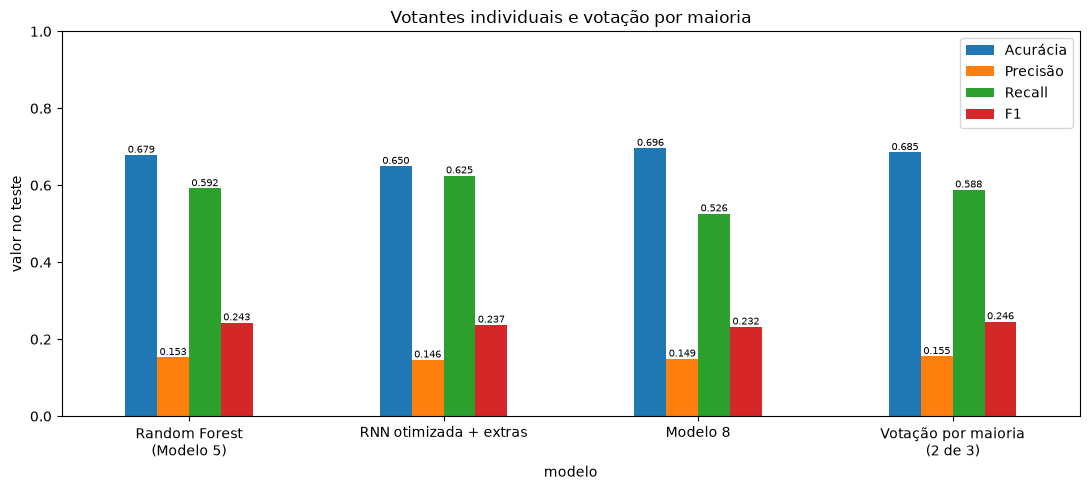

In [12]:
plot = RES[RES['modelo'] != 'Referência: nunca alerta'].set_index('modelo')[['acuracia', 'precisao', 'recall', 'f1']]
ax = plot.plot.bar(figsize=(11, 5), rot=0)
ax.set_ylabel('valor no teste')
ax.set_ylim(0, 1)
ax.set_title('Votantes individuais e votação por maioria')
ax.set_xticklabels([t.get_text().replace(' (', '\n(') for t in ax.get_xticklabels()])
for barras in ax.containers:
    ax.bar_label(barras, fmt='%.3f', fontsize=7)
ax.legend(['Acurácia', 'Precisão', 'Recall', 'F1'], loc='upper right')
plt.tight_layout()
plt.show()

## 6. Conclusão

| | Acurácia | Precisão | Recall | F1 | Alertas |
|---|---:|---:|---:|---:|---:|
| Random Forest (Modelo 5) | 67,9% | 15,3% | 59,2% | 0,243 | 24.019 |
| RNN otimizada + extras | 65,0% | 14,6% | 62,5% | 0,237 | 26.492 |
| Modelo 8 | 69,7% | 14,9% | 52,6% | 0,232 | 21.929 |
| **Votação (2 de 3)** | **68,6%** | **15,5%** | **58,8%** | **0,246** | **23.482** |

A votação tem a maior precisão e o maior F1 dos três, mas a vantagem sobre o Random Forest sozinho é pequena: F1 de 0,243 para 0,246, precisão de 15,3% para 15,5%, com 537 alertas a menos e 21 falhas a menos detectadas. A acurácia fica entre a dos votantes e muito abaixo dos 91,3% de quem nunca alerta, o que confirma que ela não serve para escolher modelo neste problema.

O ganho é pequeno porque os votantes concordam em 74% a 82% das linhas. Random Forest e Modelo 8 são árvores sobre o mesmo painel e erram em lugares parecidos; a RNN é o votante mais diferente. A maioria só decide nas linhas com 1 ou 2 votos, cerca de 31% do teste.

O sinal mais útil está no **número de votos**, não só na maioria. Nas linhas sem nenhum voto, 4,2% falham; com os três votando juntos, 18,3%. A unanimidade, sozinha, teria precisão de 18,3% com 13.421 alertas. Contar os votos (0 a 3) dá um nível de risco que pode ordenar a fila de inspeção, em vez de um único sim/não.

Duas observações sobre os números de referência:

- O Random Forest aqui é o bundle de produção (limiar salvo nele), por isso difere um pouco do notebook do Modelo 5 (precisão 15,9%, recall 55,3%).
- O código atual do Modelo 8 escolhe a cabeça Random Forest pelo F1 de validação. O resultado documentado do Modelo 8 (precisão 16,7%, recall 30,8%) vem de uma versão anterior, com limiar F0,5 e porta do Isolation Forest. Aqui o notebook foi reproduzido como está.